### Creating features: stock and 0-stock rate

This notebook will be used to create the following:

A table with 3 columns: (Column 1) date (Column 2) available stock (Column 3) 0-stock rate

In [1]:
# Obtain necessary datasets
import pandas as pd

Calendar = pd.read_csv('calendar.csv')
Inventory = pd.read_csv('inventory.csv.gz')
Products = pd.read_csv('products.csv')
Stores = pd.read_csv('stores.csv')

In [2]:
# Create a list with the item ids
item_ids = [i for i in Products['item_id']]

# Create a list with the store ids\
store_ids = [i for i in Stores['store_id']]

# Create a list with the available dates
dates = [i for i in Calendar['date']]

# Create a list with the available departments
Departments = list({i.replace(" ", "") for i in Products['department']})

# Create a dictionary where the keys are the item ids and the values are the corresponding departments
item_department_dict = {row['item_id']: row['department'].replace(" ", "") for index, row in Products.iterrows()}

# Create a list of items for each department
department_items_dict = {department: [item for item in item_ids if item_department_dict[item] == department] for department in Departments}

In [3]:
# Create a new dataset that combines that adds the departments feature to the inventory dataset
Inventory_with_departments = Inventory.copy()
Inventory_with_departments['department'] = Inventory_with_departments['item_id'].map(item_department_dict)
Inventory_with_departments

,date,store_id,item_id,on_hand,received,shrink,department
0,2024-01-03,104,971509,100,100,1,Produce
1,2024-01-03,104,652089,220,220,3,Produce
2,2024-01-03,104,329628,100,100,0,Produce
3,2024-01-03,104,406789,24,24,1,Produce
4,2024-01-03,104,813467,24,24,0,Produce
...,...,...,...,...,...,...,...
8759995,2026-01-01,318,248758,6,0,0,Health&Beauty
8759996,2026-01-01,318,175134,8,0,0,Health&Beauty
8759997,2026-01-01,318,165350,19,0,0,Health&Beauty
8759998,2026-01-01,318,980056,0,0,0,Health&Beauty


In [4]:
features_per_store_per_department = {}

for store in store_ids:
    features_per_store_per_department[store] = {}
    
    for department in Departments:
        Inventory_with_departments_per_store_per_department = Inventory_with_departments.loc[
            (Inventory_with_departments["store_id"] == store) &
            (Inventory_with_departments["department"] == department)
        ]
        
        New_table = (
            Inventory_with_departments_per_store_per_department.groupby("date", as_index=False)
              .agg(
                  total_on_hand=("on_hand", "sum"),
                  num_zero=("on_hand", lambda s: (s == 0).sum()),
                  num_items=("on_hand", "size"),
              )
        )
        
        New_table["zero_ratio"] = New_table["num_zero"] / New_table["num_items"]
        
        # Keep only the requested columns
        New_table = New_table[["date", "total_on_hand", "num_zero", "zero_ratio"]]

        features_per_store_per_department[store][department] = New_table

In [12]:
print(Departments)
print(store_ids)

['Frozen', 'Health&Beauty', 'Grocery', 'Dairy', 'Beverages', 'Household', 'Produce', 'Meat&Seafood', 'Bakery']
[104, 117, 123, 131, 208, 214, 226, 305, 311, 318]


In [38]:
features_per_store_per_department[226]['Household']

,date,total_on_hand,num_zero,zero_ratio
0,2024-01-03,1360,0,0.00
1,2024-01-04,1191,0,0.00
2,2024-01-05,1580,0,0.00
3,2024-01-06,1438,0,0.00
4,2024-01-07,1264,0,0.00
...,...,...,...,...
725,2025-12-28,1276,1,0.01
726,2025-12-29,1141,1,0.01
727,2025-12-30,1311,0,0.00
728,2025-12-31,1179,0,0.00


### Extra stuff
______________________

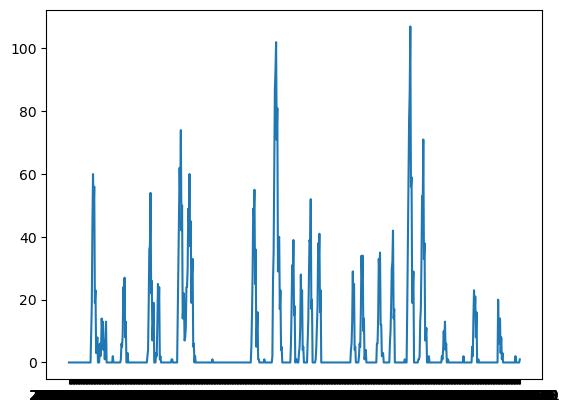

In [11]:
import matplotlib.pyplot as plt

plt.plot(features_per_store_per_department[104]['Frozen']['date'], features_per_store_per_department[104]['Frozen']['num_zero']) 

In [39]:
store = 226
department = "Household"
features_per_store_per_department[store][department]

,date,total_on_hand,num_zero,zero_ratio
0,2024-01-03,1360,0,0.00
1,2024-01-04,1191,0,0.00
2,2024-01-05,1580,0,0.00
3,2024-01-06,1438,0,0.00
4,2024-01-07,1264,0,0.00
...,...,...,...,...
725,2025-12-28,1276,1,0.01
726,2025-12-29,1141,1,0.01
727,2025-12-30,1311,0,0.00
728,2025-12-31,1179,0,0.00


In [44]:
Table = Inventory_with_departments.loc[
    (Inventory_with_departments["department"] == department) &
    (Inventory_with_departments["date"] == "2024-01-05") &
    (Inventory_with_departments["store_id"] == store)
]
Table["on_hand"].sum()

np.int64(1580)

In [26]:
Inventory_with_departments = Inventory_with_departments.loc[
    (Inventory_with_departments["store_id"] == store_ids[0])
]
Inventory_with_departments

,date,store_id,item_id,on_hand,received,shrink,department
0,2024-01-03,104,971509,100,100,1,Produce
1,2024-01-03,104,652089,220,220,3,Produce
2,2024-01-03,104,329628,100,100,0,Produce
3,2024-01-03,104,406789,24,24,1,Produce
4,2024-01-03,104,813467,24,24,0,Produce
...,...,...,...,...,...,...,...
8749195,2026-01-01,104,248758,5,0,0,Health&Beauty
8749196,2026-01-01,104,175134,10,0,0,Health&Beauty
8749197,2026-01-01,104,165350,14,0,0,Health&Beauty
8749198,2026-01-01,104,980056,15,0,0,Health&Beauty


In [30]:
date_on_hand = (
    Inventory_with_departments
        .loc[
        (Inventory_with_departments["department"] == Departments[0])
        ]
        .groupby("date", as_index=False)["on_hand"]
        .sum()
        .rename(columns={"on hand": "total_on_hand"})
)

date_on_hand

,date,on_hand
0,2024-01-03,1092
1,2024-01-04,945
2,2024-01-05,1412
3,2024-01-06,1261
4,2024-01-07,1055
...,...,...
725,2025-12-28,1103
726,2025-12-29,930
727,2025-12-30,1143
728,2025-12-31,1001


In [37]:
import pandas as pd

result = (
    Inventory_with_departments.groupby("date", as_index=False)
      .agg(
          total_on_hand=("on_hand", "sum"),
          num_zero=("on_hand", lambda s: (s == 0).sum()),
          num_items=("on_hand", "size"),
      )
)

print(result)

result["zero_ratio"] = result["num_zero"] / result["num_items"]

print(result)

# Keep only the requested columns
result = result[["date", "total_on_hand", "zero_ratio"]]
result

           date  total_on_hand  num_zero  num_items
0    2024-01-03          25789         0       1200
1    2024-01-04          23232         0       1200
2    2024-01-05          23770         0       1200
3    2024-01-06          30218         0       1200
4    2024-01-07          21302         1       1200
..          ...            ...       ...        ...
725  2025-12-28          21388        80       1200
726  2025-12-29          21572         0       1200
727  2025-12-30          22047         0       1200
728  2025-12-31          22317         0       1200
729  2026-01-01          17809         1       1200

[730 rows x 4 columns]
           date  total_on_hand  num_zero  num_items  zero_ratio
0    2024-01-03          25789         0       1200    0.000000
1    2024-01-04          23232         0       1200    0.000000
2    2024-01-05          23770         0       1200    0.000000
3    2024-01-06          30218         0       1200    0.000000
4    2024-01-07          21302  

,date,total_on_hand,zero_ratio
0,2024-01-03,25789,0.000000
1,2024-01-04,23232,0.000000
2,2024-01-05,23770,0.000000
3,2024-01-06,30218,0.000000
4,2024-01-07,21302,0.000833
...,...,...,...
725,2025-12-28,21388,0.066667
726,2025-12-29,21572,0.000000
727,2025-12-30,22047,0.000000
728,2025-12-31,22317,0.000000


In [18]:
Inventory_with_departments_104_Produce = Inventory_with_departments_104.loc[
    (Inventory_with_departments_104["department"] == Departments[0]) &
    (Inventory_with_departments_104["date"] == dates[729])
]
Inventory_with_departments_104_Produce["on_hand"].sum()

np.int64(780)

In [16]:
Inventory_with_departments_104_Produce = Inventory_with_departments_104.loc[
    (Inventory_with_departments_104["department"] == Departments[0])
]
Inventory_with_departments_104_Produce

,date,store_id,item_id,on_hand,received,shrink,department
1120,2024-01-03,104,601123,12,12,0,Health&Beauty
1121,2024-01-03,104,455189,12,12,0,Health&Beauty
1122,2024-01-03,104,480739,12,12,0,Health&Beauty
1123,2024-01-03,104,604356,12,12,0,Health&Beauty
1124,2024-01-03,104,816395,12,12,0,Health&Beauty
...,...,...,...,...,...,...,...
8749195,2026-01-01,104,248758,5,0,0,Health&Beauty
8749196,2026-01-01,104,175134,10,0,0,Health&Beauty
8749197,2026-01-01,104,165350,14,0,0,Health&Beauty
8749198,2026-01-01,104,980056,15,0,0,Health&Beauty


In [21]:
import pandas as pd

# Assuming your DataFrame is called `df`
date_on_hand = (
    Inventory_with_departments_104_Produce.groupby("date", as_index=False)["on_hand"]
      .sum()
      .rename(columns={"on hand": "total_on_hand"})
)

print(date_on_hand)

         date  on_hand
0  2026-01-01      780
